# Predicting Online Ad Clicks with a Random Forest
**ML Mini Project No. 34 · A.Y. 2025-26**

**Problem.** An advertiser pays for every ad impression, but only some users click. If we can tell in advance which
visitors are likely to click, budget can be spent on them instead of on users who never will.

**Objective.** Train a Random Forest classifier that predicts `Clicked on Ad` (1 / 0) from a user's browsing behaviour
and demographics. Tune it, evaluate it honestly on unseen data, compare it with other algorithms, and explain what the
model tells an advertising team.

| Rubric item | Where in this notebook |
|---|---|
| 1. Dataset understanding | Section 1 |
| 2. Data preprocessing | Section 3 |
| 3. Algorithm implementation (manual) | Section 4: Random Forest from scratch |
| 4. Algorithm application | Section 5 |
| 5. Parameter tuning | Section 6 |
| 6. Evaluation + manual metric calculation | Section 7 |
| 7. Comparison / analysis | Section 9 |
| 8. Visualisation | Sections 2, 6, 7, 8, 9 |
| 9. Interpretation & discussion | Section 10 |

The same pipeline powers the interactive dashboard in `app/` (run `python app/app.py`).

In [1]:
import sys, time, inspect, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)

from ml.features import FeatureBuilder, FEATURES, NUMERIC_RAW, DROPPED, TARGET, load_raw
from ml.scratch_forest import ScratchForest, ScratchTree, gini

SEED = 42
C0, C1, ACCENT, S3 = "#3A6EA8", "#BC7A22", "#2C5D93", "#1BA58A"   # not clicked, clicked, model, comparison
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.family": "Segoe UI", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#C3C9D1",
    "axes.grid": True, "grid.color": "#E8EBEE", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "semibold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.labelcolor": "#485361", "xtick.color": "#7A8491", "ytick.color": "#7A8491",
    "legend.frameon": False, "figure.facecolor": "#FBFBFA", "axes.facecolor": "#FBFBFA",
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png")

## 1. Dataset understanding

The **Advertising** dataset (public, widely used for click prediction) logs 1,000 ad impressions. Each row describes
the user who saw the ad, when it was shown, and whether they clicked.

In [2]:
df = load_raw(ROOT / "data" / "advertising.csv")
print("Shape:", df.shape)
df.head()

Shape: (1000, 10)


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
summary

,dtype,missing,unique,example
Daily Time Spent on Site,float64,0,900,68.95
Age,int64,0,43,35
Area Income,float64,0,1000,61833.9
Daily Internet Usage,float64,0,966,256.09
Ad Topic Line,str,0,1000,Cloned 5thgeneration orchestration
City,str,0,969,Wrightburgh
Male,int64,0,2,0
Country,str,0,237,Tunisia
Timestamp,datetime64[us],0,1000,2016-03-27 00:53:11
Clicked on Ad,int64,0,2,0


In [4]:
df[NUMERIC_RAW].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Daily Time Spent on Site,1000.0,65.00,15.85,32.60,51.36,68.22,78.55,91.43
Age,1000.0,36.01,8.79,19.00,29.00,35.00,42.00,61.00
Area Income,1000.0,55000.00,13414.63,13996.50,47031.80,57012.30,65470.63,79484.80
Daily Internet Usage,1000.0,180.00,43.90,104.78,138.83,183.13,218.79,269.96


In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df.Timestamp.min().date(), "->", df.Timestamp.max().date())
print(df[TARGET].value_counts().rename({0: "not clicked", 1: "clicked"}))

Duplicate rows: 0
Date range: 2016-01-01 -> 2016-07-24
Clicked on Ad
not clicked    500
clicked        500
Name: count, dtype: int64


**What the data looks like, in plain words.**

* **1,000 rows, 10 columns, no missing values, no duplicates.** No imputation is needed.
* **Target:** `Clicked on Ad` is binary and **perfectly balanced (500 / 500)**. Accuracy is therefore a fair
  headline metric and no over/under-sampling is required.
* **Four continuous features:** daily minutes on the site, age, average income of the user's area, and daily
  minutes on the internet overall.
* **One binary feature:** `Male`.
* **One timestamp:** January to July 2016.
* **Three text columns:** `Ad Topic Line` (1,000 unique), `City` (969 unique) and `Country` (237 unique). These
  behave like row identifiers rather than categories, which matters for preprocessing.

## 2. Exploratory analysis

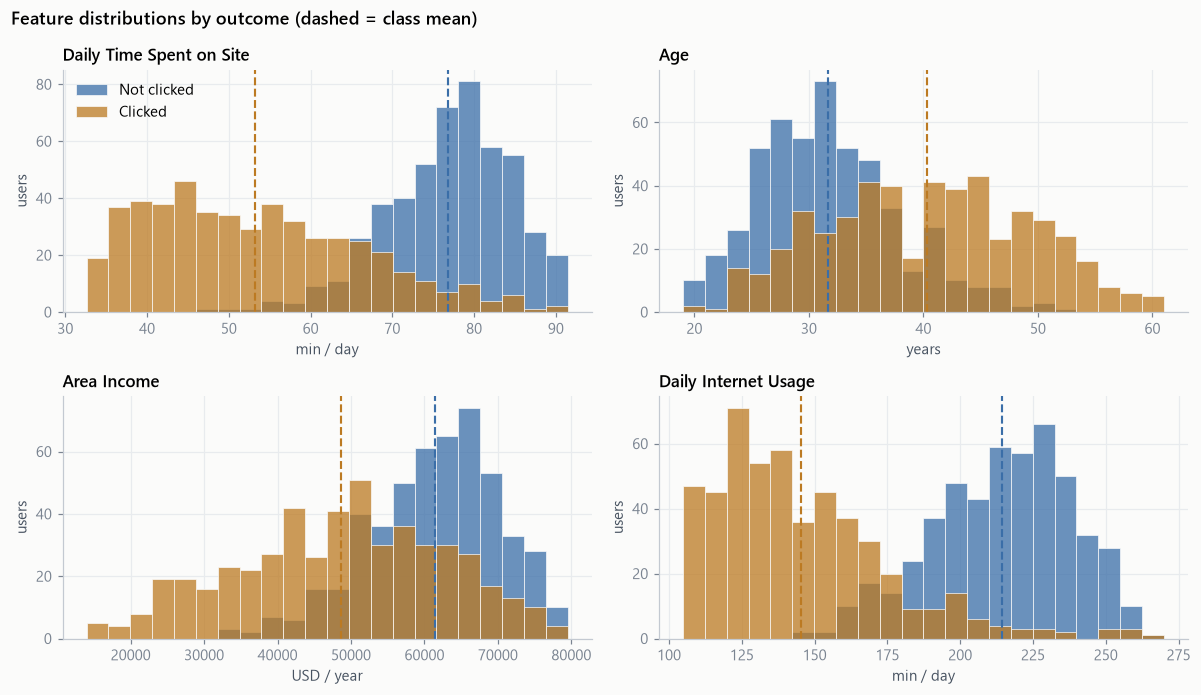

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
units = {"Daily Time Spent on Site": "min / day", "Age": "years", "Area Income": "USD / year", "Daily Internet Usage": "min / day"}
for ax, col in zip(axes.flat, NUMERIC_RAW):
    bins = np.histogram_bin_edges(df[col], bins=22)
    for y, c, lab in ((0, C0, "Not clicked"), (1, C1, "Clicked")):
        ax.hist(df.loc[df[TARGET] == y, col], bins=bins, color=c, alpha=.75, label=lab, edgecolor="#FBFBFA", linewidth=.6)
        ax.axvline(df.loc[df[TARGET] == y, col].mean(), color=c, lw=1.4, ls="--")
    ax.set_title(col); ax.set_xlabel(units[col]); ax.set_ylabel("users")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Feature distributions by outcome (dashed = class mean)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); save(fig, "01_distributions"); plt.show()

Every numeric feature separates the classes clearly:

* **Clickers spend less time on the site** (about 53 vs. 77 minutes) and **much less time online overall**
  (about 146 vs. 214 minutes).
* **Clickers are older** (about 40 vs. 32 years) and live in **lower-income areas**.

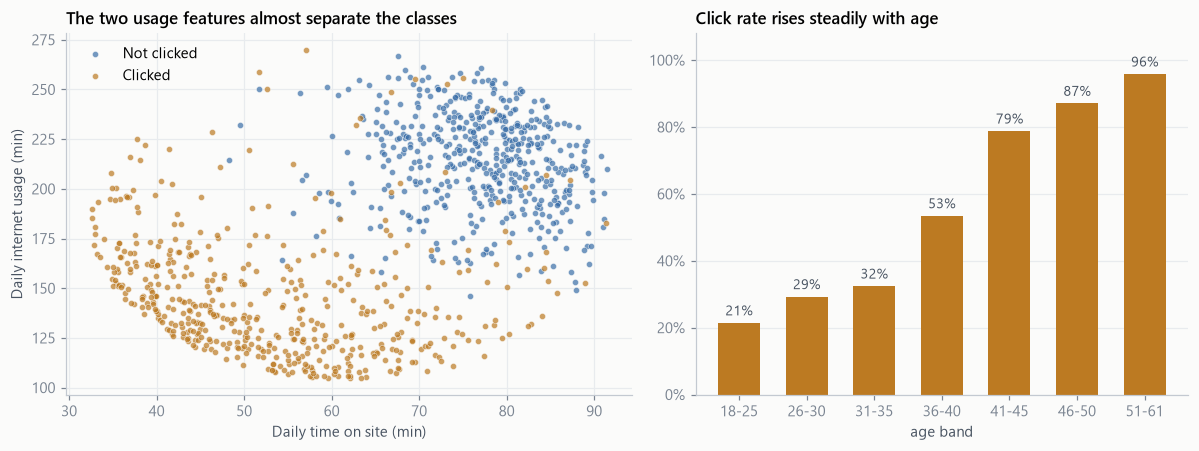

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
for y, c, lab in ((0, C0, "Not clicked"), (1, C1, "Clicked")):
    s = df[df[TARGET] == y]
    a.scatter(s["Daily Time Spent on Site"], s["Daily Internet Usage"], s=16, color=c, alpha=.7, label=lab, edgecolor="#FBFBFA", linewidth=.4)
a.set_xlabel("Daily time on site (min)"); a.set_ylabel("Daily internet usage (min)")
a.set_title("The two usage features almost separate the classes"); a.legend(loc="upper left")

bands = pd.cut(df.Age, [18, 25, 30, 35, 40, 45, 50, 61], labels=["18-25", "26-30", "31-35", "36-40", "41-45", "46-50", "51-61"], include_lowest=True)
rate = df.groupby(bands, observed=True)[TARGET].mean()
bars = b.bar(rate.index.astype(str), rate.values, color=C1, width=.62)
b.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=3, fontsize=9, color="#485361")
b.set_ylim(0, 1.08); b.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
b.set_title("Click rate rises steadily with age"); b.set_xlabel("age band"); b.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "02_scatter_age"); plt.show()

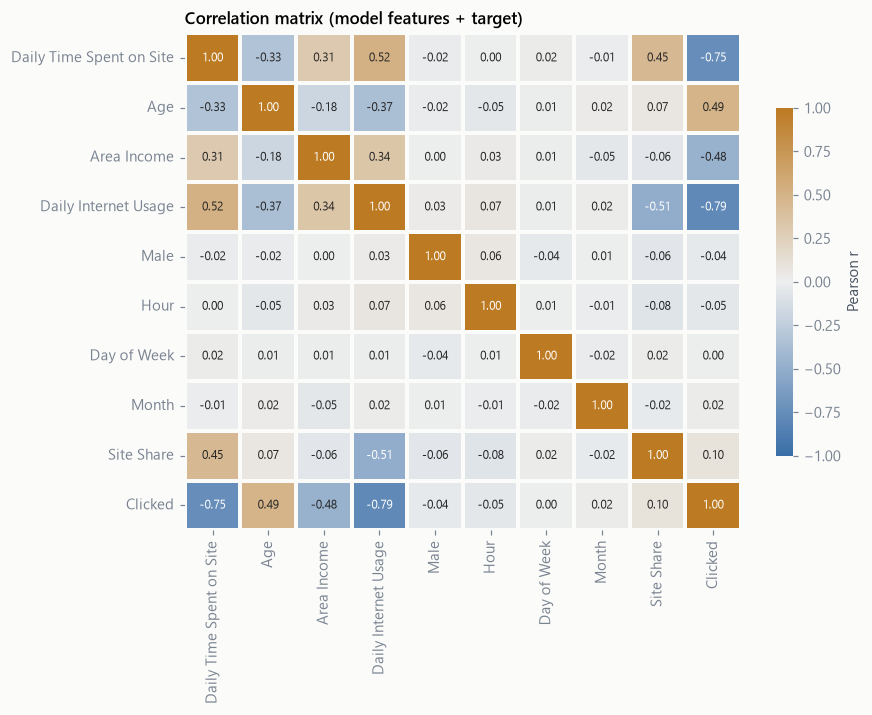

In [8]:
feat_all = FeatureBuilder(clip=False).fit(df).transform(df).assign(**{"Clicked": df[TARGET].values})
corr = feat_all.corr()
cmap = mpl.colors.LinearSegmentedColormap.from_list("bluegreyamber", [C0, "#ECEDEE", C1])
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1.5, linecolor="#FBFBFA",
            cbar_kws={"shrink": .7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix (model features + target)"); ax.grid(False)
fig.tight_layout(); save(fig, "03_correlation"); plt.show()

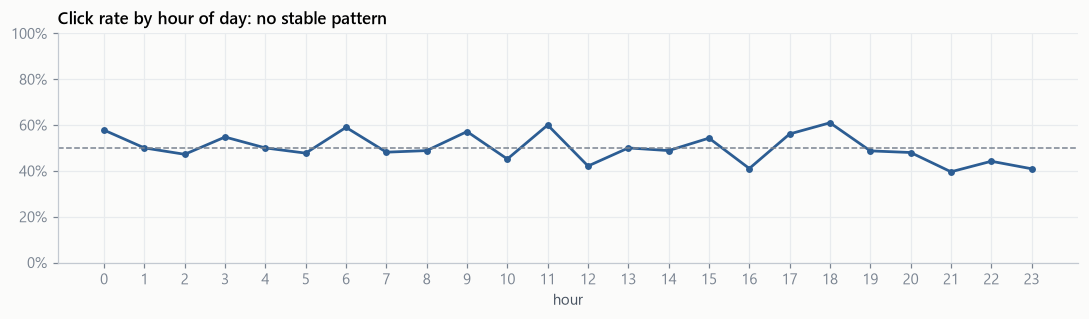

rows per hour: min 31 max 54


In [9]:
by_hour = df.groupby(df.Timestamp.dt.hour)[TARGET].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(by_hour.index, by_hour["mean"], color=ACCENT, marker="o", ms=3.5, lw=1.8)
ax.axhline(.5, color="#7A8491", ls="--", lw=1)
ax.set_xticks(range(24)); ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_title("Click rate by hour of day: no stable pattern"); ax.set_xlabel("hour")
fig.tight_layout(); save(fig, "04_hour"); plt.show()
print("rows per hour: min", by_hour["count"].min(), "max", by_hour["count"].max())

**What exploration tells us before any modelling.**

* `Daily Internet Usage` (r = −0.79) and `Daily Time Spent on Site` (r = −0.75) are the strongest single signals.
* `Age` (+0.49) and `Area Income` (−0.48) come next.
* `Male`, hour, day and month are essentially uncorrelated with clicking. The hourly swings come from roughly 40
  rows per hour, which is noise rather than a real timing effect.
* The scatter plot shows the classes split along a **nearly straight diagonal**. This matters later: it explains
  why a simple linear model is a strong competitor on this dataset.

## 3. Preprocessing

All steps live in one `FeatureBuilder` transformer (`ml/features.py`) so that the **exact same code** runs in
cross-validation, on the test set and in the live web app.

In [10]:
print(inspect.getsource(FeatureBuilder))

class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Turns a raw advertising dataframe into the model feature matrix.

    fit()       learns IQR clipping bounds for the numeric columns
    transform() builds calendar features, the Site Share ratio, and clips outliers
    """

    def __init__(self, iqr_factor=1.5, clip=True):
        self.iqr_factor = iqr_factor
        self.clip = clip

    def fit(self, X, y=None):
        self.bounds_ = {}
        for col in NUMERIC_RAW:
            q1, q3 = np.percentile(X[col], [25, 75])
            iqr = q3 - q1
            self.bounds_[col] = (q1 - self.iqr_factor * iqr, q3 + self.iqr_factor * iqr)
        return self

    def transform(self, X):
        X = X.copy()
        ts = pd.to_datetime(X["Timestamp"])
        out = pd.DataFrame(index=X.index)
        for col in NUMERIC_RAW:
            vals = X[col].astype(float)
            if self.clip:
                lo, hi = self.bounds_[col]
                vals = vals.clip(lo, hi)
     

| Step | What | Why |
|---|---|---|
| Drop `Ad Topic Line`, `City`, `Country` | 100% / 97% / 24% unique values | They act as identifiers. One-hot encoding Country would add 237 sparse columns for 1,000 rows, so trees would memorise rather than generalise. |
| Decompose `Timestamp` | → `Hour`, `Day of Week`, `Month` | A raw datetime cannot be split on. If timing mattered, these columns would reveal it. |
| Cap outliers (IQR rule) | clip to Q1 − 1.5·IQR … Q3 + 1.5·IQR | Trees are robust, but the linear/KNN/SVM baselines are not. Bounds are learned on **training data only**. |
| Engineer `Site Share` | time on site ÷ internet usage | The share of a user's online day spent on this site, a possible interaction signal. |
| Encoding | none needed | `Male` is already 0/1 and no text columns remain. |
| Scaling | **not** applied for the forest | A split `x ≤ t` is unaffected by any monotonic rescaling. `StandardScaler` is added only inside the LR/KNN/SVM pipelines. |

In [11]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=[TARGET]); y = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape, "| click share train/test:", y_train.mean(), y_test.mean())

fb = FeatureBuilder().fit(X_train)
for col, (lo, hi) in fb.bounds_.items():
    n_out = ((X_train[col] < lo) | (X_train[col] > hi)).sum()
    print(f"{col:<26} bounds [{lo:>10.2f}, {hi:>10.2f}]   clipped in train: {n_out}")
A_train, A_test = fb.transform(X_train), fb.transform(X_test)
A_train.head()

train (750, 9) test (250, 9) | click share train/test: 0.5 0.5
Daily Time Spent on Site   bounds [     10.79,     119.38]   clipped in train: 0
Age                        bounds [      9.88,      60.88]   clipped in train: 1
Area Income                bounds [  20035.33,   93517.53]   clipped in train: 6
Daily Internet Usage       bounds [     20.66,     337.89]   clipped in train: 0


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Hour,Day of Week,Month,Site Share
232,62.42,38.0,74445.18,143.94,0,7,1,7,0.433653
586,78.29,38.0,57844.96,252.07,0,20,1,1,0.310588
521,63.26,29.0,54787.37,120.46,1,4,2,3,0.525154
295,82.40,36.0,66744.65,218.97,1,3,2,6,0.376307
578,66.89,23.0,64433.99,208.24,1,7,0,1,0.321216


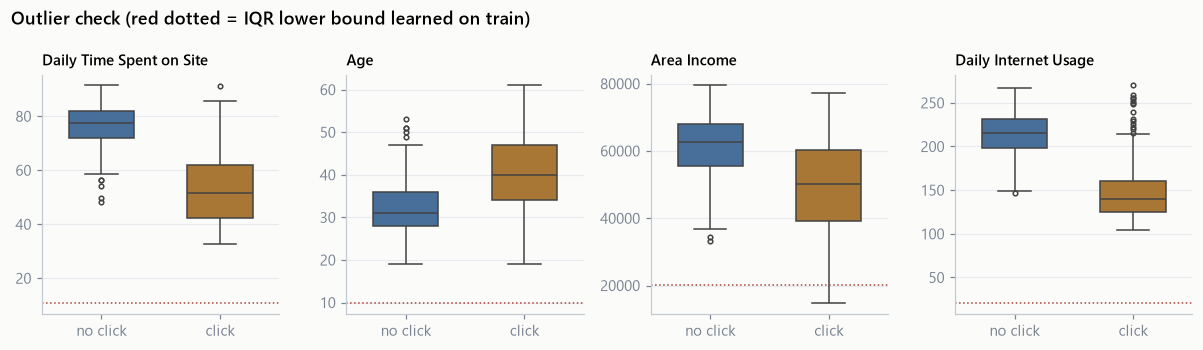

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, col in zip(axes, NUMERIC_RAW):
    sns.boxplot(x=y_train, y=X_train[col].values, hue=y_train, palette=[C0, C1], legend=False, ax=ax,
                width=.55, fliersize=3, linewidth=1)
    lo, hi = fb.bounds_[col]
    ax.axhline(lo, color="#A94438", ls=":", lw=1)
    ax.set_title(col, fontsize=9.5); ax.set_xlabel(""); ax.set_ylabel(""); ax.set_xticks([0, 1], ["no click", "click"])
fig.suptitle("Outlier check (red dotted = IQR lower bound learned on train)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); save(fig, "05_outliers"); plt.show()

Only `Area Income` has real outliers: a handful of very low-income areas, mostly clickers. Clipping them to the lower
bound (≈ $20k) keeps them in the data while stopping extreme values from dominating scale-sensitive baselines.

## 4. Random Forest implemented from scratch

To show how the algorithm works, `ml/scratch_forest.py` implements it with **NumPy only**:

1. **Gini impurity** of a node: $G = 1 - p_1^2 - p_0^2$
2. **Best split:** for each candidate feature, sort the values once and use a running count of positives to score
   every possible threshold in $O(n)$. Keep the split with the largest impurity decrease
   $\Delta = G_{parent} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$.
3. **Grow the tree** recursively until a node is pure, too small, or at max depth.
4. **Bagging:** each tree is trained on a bootstrap sample (n rows drawn *with replacement*).
5. **Random subspace:** at every split only $\sqrt{p}$ randomly chosen features are considered, which de-correlates the trees.
6. **Predict** by averaging the trees' class probabilities. Rows a tree never saw (out-of-bag) give a free validation score.

### 4.1 One split, calculated by hand

In [13]:
# Tiny example: 10 users, internet usage (min) and whether they clicked
usage = np.array([120, 135, 150, 160, 175, 190, 205, 220, 240, 255])
click = np.array([  1,   1,   1,   1,   0,   1,   0,   0,   0,   0])

parent = gini(click.sum(), len(click))
print(f"Parent: 5 clicks / 10  ->  G = 1 - 0.5^2 - 0.5^2 = {parent:.3f}\n")
rows = []
for i in range(1, len(usage)):
    thr = (usage[i-1] + usage[i]) / 2
    L, R = click[:i], click[i:]
    gl, gr = gini(L.sum(), len(L)), gini(R.sum(), len(R))
    w = len(L)/10*gl + len(R)/10*gr
    rows.append((thr, f"{L.sum()}/{len(L)}", f"{R.sum()}/{len(R)}", round(gl, 3), round(gr, 3), round(w, 3), round(parent - w, 3)))
pd.DataFrame(rows, columns=["threshold", "left clicks", "right clicks", "G_left", "G_right", "weighted G", "decrease"])

Parent: 5 clicks / 10  ->  G = 1 - 0.5^2 - 0.5^2 = 0.500



,threshold,left clicks,right clicks,G_left,G_right,weighted G,decrease
0,127.5,1/1,4/9,0.000,0.494,0.444,0.056
1,142.5,2/2,3/8,0.000,0.469,0.375,0.125
2,155.0,3/3,2/7,0.000,0.408,0.286,0.214
3,167.5,4/4,1/6,0.000,0.278,0.167,0.333
4,182.5,4/5,1/5,0.320,0.320,0.320,0.180
5,197.5,5/6,0/4,0.278,0.000,0.167,0.333
6,212.5,5/7,0/3,0.408,0.000,0.286,0.214
7,230.0,5/8,0/2,0.469,0.000,0.375,0.125
8,247.5,5/9,0/1,0.494,0.000,0.444,0.056


**Worked example for the threshold 167.5.**

* Left node: 4 clicks out of 4, so $G_L = 1 - 1^2 - 0^2 = 0$.
* Right node: 1 click out of 6, so $G_R = 1 - (1/6)^2 - (5/6)^2 = 0.278$.
* Weighted impurity: $0.4 \cdot 0 + 0.6 \cdot 0.278 = 0.167$.
* Decrease: $0.5 - 0.167 = 0.333$, the largest in the table. The tree therefore splits on **usage ≤ 167.5**.

The scratch `ScratchTree._best_split` performs exactly this search, vectorised.

In [14]:
print(inspect.getsource(ScratchTree._best_split))

    def _best_split(self, X, y):
        """Search every candidate threshold on a random subset of features.

        For one feature, sort the samples once; a running sum of positives then
        gives the class counts on each side of every possible cut in O(n).
        """
        n = len(y)
        k = self.max_features or self.n_features_
        candidates = self.rng.choice(self.n_features_, size=k, replace=False)

        parent = gini(y.sum(), n)
        best = (None, None, 0.0)            # feature, threshold, impurity decrease
        leaf = self.min_samples_leaf

        for f in candidates:
            order = np.argsort(X[:, f], kind="mergesort")
            xs, ys = X[order, f], y[order]
            pos_left = np.cumsum(ys)[:-1]            # positives left of cut i+1
            n_left = np.arange(1, n)
            n_right = n - n_left
            pos_right = ys.sum() - pos_left

            p_l = pos_left / n_left
            p_r = pos_right / n_right
            g_l = 1

### 4.2 Train the scratch forest and compare with scikit-learn (same settings)

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

t = time.time(); scratch = ScratchForest(n_estimators=100, max_features="sqrt", random_state=SEED).fit(A_train.values, y_train); t_s = time.time() - t
t = time.time(); sk = RandomForestClassifier(n_estimators=100, max_features="sqrt", oob_score=True, random_state=SEED).fit(A_train, y_train); t_k = time.time() - t
p_s, p_k = scratch.predict_proba(A_test.values)[:, 1], sk.predict_proba(A_test)[:, 1]

def scores(p):
    yhat = (p >= .5).astype(int)
    return [accuracy_score(y_test, yhat), precision_score(y_test, yhat), recall_score(y_test, yhat), f1_score(y_test, yhat), roc_auc_score(y_test, p)]
cmp = pd.DataFrame([scores(p_s) + [scratch.oob_score_, t_s], scores(p_k) + [sk.oob_score_, t_k]],
                   index=["From scratch (NumPy)", "scikit-learn"], columns=["accuracy", "precision", "recall", "F1", "ROC-AUC", "OOB acc", "fit s"]).round(3)
print("Prediction agreement:", ((p_s >= .5) == (p_k >= .5)).mean())
cmp

Prediction agreement: 0.992


,accuracy,precision,recall,F1,ROC-AUC,OOB acc,fit s
From scratch (NumPy),0.960,0.960,0.96,0.960,0.989,0.965,0.840
scikit-learn,0.968,0.976,0.96,0.968,0.990,0.965,0.229


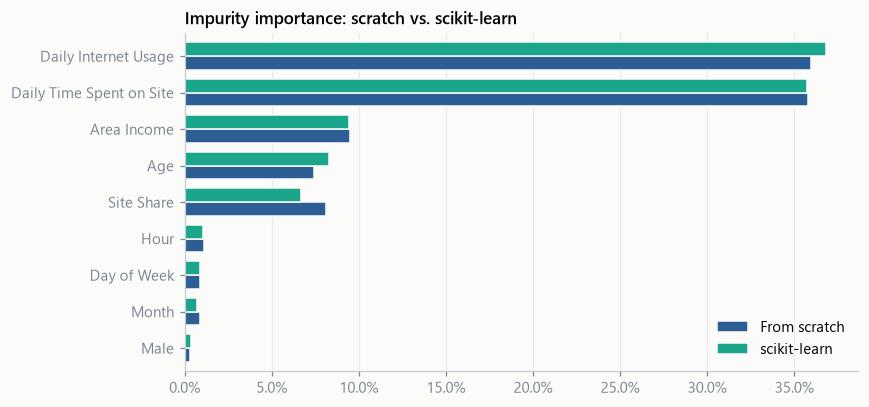

In [16]:
imp = pd.DataFrame({"From scratch": scratch.feature_importances_, "scikit-learn": sk.feature_importances_}, index=FEATURES).sort_values("scikit-learn")
fig, ax = plt.subplots(figsize=(8, 3.8))
imp.plot.barh(ax=ax, color=[ACCENT, S3], width=.75, edgecolor="#FBFBFA")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.set_title("Impurity importance: scratch vs. scikit-learn"); ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "06_scratch_importance"); plt.show()

The from-scratch forest reaches almost the same accuracy and AUC, the **same OOB score**, and nearly identical
feature importances. The small differences come from different random draws, not different logic. This confirms
the implementation is correct. scikit-learn is faster because its tree builder is compiled C/Cython.

### 4.3 Watching the vote: the hardest test row

In [17]:
votes = scratch.tree_votes(A_test.values)                 # shape (100 trees, 250 rows)
share = (votes >= .5).mean(axis=0)
i = int(np.argmin(np.abs(share - .5)))
print("Hardest test row:"); print(A_test.iloc[i].round(3).to_string())
print(f"\n{int((votes[:, i] >= .5).sum())} of 100 trees vote 'click', mean P = {votes[:, i].mean():.2f}, true label = {y_test[i]}")

Hardest test row:
Daily Time Spent on Site       89.370
Age                            34.000
Area Income                 42760.220
Daily Internet Usage          162.030
Male                            1.000
Hour                           12.000
Day of Week                     5.000
Month                           4.000
Site Share                      0.552

51 of 100 trees vote 'click', mean P = 0.51, true label = 0


This visitor combines non-clicker traits (89 minutes on the site) with clicker traits (a low-income area, moderate
internet use). The trees split almost evenly, and the forest tips the wrong way by a single vote. Errors like this
sit right on the class boundary, which is expected and honest behaviour.

## 5. Random Forest with scikit-learn

The production model wraps `FeatureBuilder` and `RandomForestClassifier` in one `Pipeline`. During
cross-validation, the outlier bounds are then re-learned inside each fold, so nothing leaks from validation rows.

| Hyperparameter | What it controls |
|---|---|
| `n_estimators` | Number of trees. More trees means a lower-variance average, with diminishing returns. |
| `max_depth` | Maximum tree depth. Deep trees memorise; shallow ones underfit. |
| `max_features` | Features tried per split. Fewer means more de-correlated trees. |
| `min_samples_split` / `min_samples_leaf` | Minimum rows needed to split / allowed in a leaf. Larger values smooth predictions. |
| `bootstrap` | Draw rows with replacement (enables OOB scoring). |
| `criterion` | Split-quality measure: Gini or entropy. |

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
default_rf = Pipeline([("features", FeatureBuilder()), ("rf", RandomForestClassifier(random_state=SEED))])
s = cross_val_score(default_rf, X_train, y_train, cv=CV)
print(f"Default forest 5-fold CV accuracy: {s.mean():.4f} ± {s.std():.4f}")

Default forest 5-fold CV accuracy: 0.9627 ± 0.0161


## 6. Hyperparameter tuning

**Randomized search** samples 60 configurations from the distributions below and scores each with 5-fold
stratified CV (300 fits). Random search covers the space more efficiently than a full grid when only a few
parameters really matter.

**Selection metric: ROC-AUC.** It measures ranking quality across all thresholds, and on 150-row folds it is far
less jumpy than accuracy, where one row equals 0.67 percentage points.

In [19]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
pipe = Pipeline([("features", FeatureBuilder()), ("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1))])
space = {
    "rf__n_estimators": randint(100, 601),
    "rf__max_depth": [None, 4, 6, 8, 10, 12, 16],
    "rf__max_features": ["sqrt", "log2", 0.5, 0.7, None],
    "rf__min_samples_split": randint(2, 21),
    "rf__min_samples_leaf": randint(1, 11),
    "rf__bootstrap": [True, False],
    "rf__criterion": ["gini", "entropy"],
}
search = RandomizedSearchCV(pipe, space, n_iter=60, cv=CV, random_state=SEED, n_jobs=-1,
                            scoring={"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}, refit="roc_auc", return_train_score=True)
t = time.time(); search.fit(X_train, y_train); print(f"search took {time.time()-t:.0f}s")
best = search.best_estimator_
print("Best parameters:", {k.replace('rf__', ''): v for k, v in search.best_params_.items()})
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_roc_auc")
res[["rank_test_roc_auc", "mean_test_roc_auc", "mean_test_accuracy", "mean_train_accuracy"] + [c for c in res if c.startswith("param_")]].head(8).round(4)

search took 39s
Best parameters: {'bootstrap': True, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 167}


,rank_test_roc_auc,mean_test_roc_auc,mean_test_accuracy,mean_train_accuracy,param_rf__bootstrap,param_rf__criterion,param_rf__max_depth,param_rf__max_features,param_rf__min_samples_leaf,param_rf__min_samples_split,param_rf__n_estimators
47,1,0.9918,0.9587,0.9830,True,entropy,10,sqrt,4,2,167
22,2,0.9914,0.9573,0.9837,True,entropy,16,sqrt,4,5,321
46,3,0.9910,0.9613,0.9937,True,gini,10,log2,2,3,409
33,4,0.9909,0.9547,0.9753,True,gini,6,log2,5,13,317
27,5,0.9908,0.9573,0.9783,True,gini,12,sqrt,4,14,332
39,6,0.9907,0.9507,0.9847,False,entropy,16,log2,8,2,366
54,6,0.9907,0.9560,0.9780,True,gini,10,sqrt,5,4,287
16,8,0.9907,0.9533,0.9760,True,gini,None,0.5,5,11,330


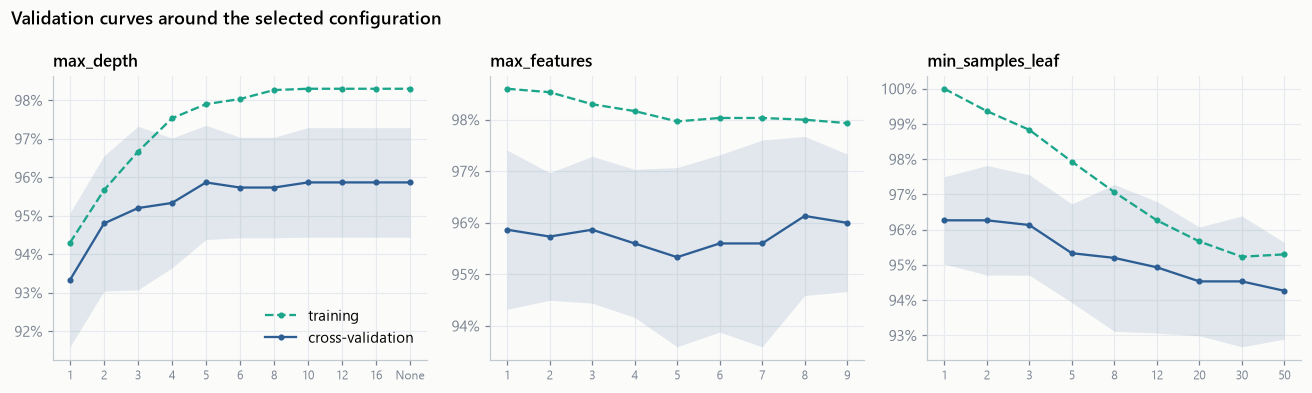

In [20]:
from sklearn.model_selection import validation_curve
rf_params = best.named_steps["rf"].get_params()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (param, values) in zip(axes, [("max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, None]),
                                       ("max_features", list(range(1, 10))),
                                       ("min_samples_leaf", [1, 2, 3, 5, 8, 12, 20, 30, 50])]):
    tr, te = validation_curve(RandomForestClassifier(**{**rf_params, "n_jobs": -1}), A_train, y_train,
                              param_name=param, param_range=values, cv=CV, n_jobs=-1)
    xs = range(len(values))
    ax.plot(xs, tr.mean(1), color=S3, ls="--", marker="o", ms=3, label="training")
    ax.plot(xs, te.mean(1), color=ACCENT, marker="o", ms=3, label="cross-validation")
    ax.fill_between(xs, te.mean(1) - te.std(1), te.mean(1) + te.std(1), color=ACCENT, alpha=.12, lw=0)
    ax.set_xticks(list(xs), [str(v) for v in values], fontsize=8); ax.set_title(param)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
axes[0].legend(loc="lower right")
fig.suptitle("Validation curves around the selected configuration", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); save(fig, "07_validation_curves"); plt.show()

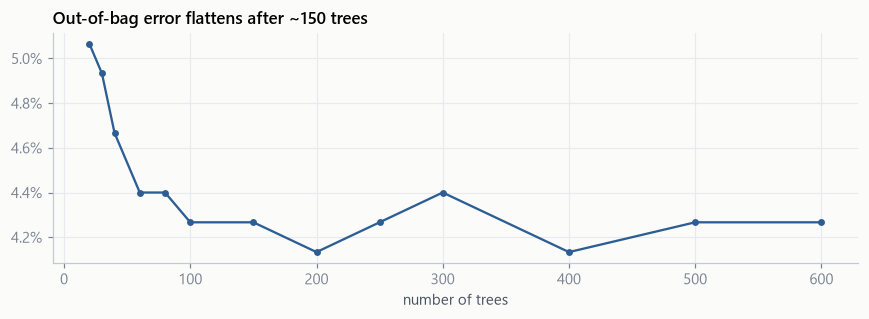

In [21]:
warm = RandomForestClassifier(**{**rf_params, "bootstrap": True, "oob_score": True, "warm_start": True, "n_estimators": 20, "n_jobs": -1})
ns, errs = [20, 30, 40, 60, 80, 100, 150, 200, 250, 300, 400, 500, 600], []
for n in ns:
    warm.set_params(n_estimators=n).fit(A_train, y_train); errs.append(1 - warm.oob_score_)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ns, errs, color=ACCENT, marker="o", ms=3.5)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=1))
ax.set_xlabel("number of trees"); ax.set_title("Out-of-bag error flattens after ~150 trees")
fig.tight_layout(); save(fig, "08_oob"); plt.show()

**Reading the tuning results.**

* **`max_depth`:** shallow trees (1–3) underfit. Beyond depth ≈ 5 the CV score plateaus while training accuracy
  keeps rising, so the extra depth only memorises. The search chose a cap of **10**.
* **`max_features`:** a small subset per split (≈ √9 = 3) works best because it de-correlates the trees. The
  search chose **sqrt**.
* **`min_samples_leaf`:** moderate leaves (≈ 4) smooth the probabilities. Very large leaves underfit.
* **`n_estimators`:** OOB error stops improving after ~150 trees, so the chosen **167** is enough. More trees
  would add cost without accuracy.
* **Net effect:** the tuned forest has training accuracy around 98.5% instead of the default 100%, with the
  same CV accuracy. It is a **less over-fitted model**, which is what you want before deployment.

## 7. Evaluation on the held-out test set (250 rows, never used for training or tuning)

In [22]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, average_precision_score
prob = best.predict_proba(X_test)[:, 1]
pred = (prob >= .5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(classification_report(y_test, pred, target_names=["not clicked", "clicked"], digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))

              precision    recall  f1-score   support

 not clicked     0.9603    0.9680    0.9641       125
     clicked     0.9677    0.9600    0.9639       125

    accuracy                         0.9640       250
   macro avg     0.9640    0.9640    0.9640       250
weighted avg     0.9640    0.9640    0.9640       250

ROC-AUC: 0.9914


### 7.1 Manual metric calculation (from the confusion matrix)

In [23]:
print(f"TP = {tp}   FP = {fp}   TN = {tn}   FN = {fn}   N = {tp+fp+tn+fn}\n")
acc  = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp)
rec  = tp / (tp + fn)
f1   = 2 * prec * rec / (prec + rec)
spec = tn / (tn + fp)
print(f"Accuracy    = (TP+TN)/N       = ({tp}+{tn})/{tp+tn+fp+fn}        = {acc:.4f}")
print(f"Precision   = TP/(TP+FP)      = {tp}/({tp}+{fp})              = {prec:.4f}")
print(f"Recall      = TP/(TP+FN)      = {tp}/({tp}+{fn})              = {rec:.4f}")
print(f"F1          = 2PR/(P+R)       = 2·{prec:.4f}·{rec:.4f}/({prec:.4f}+{rec:.4f}) = {f1:.4f}")
print(f"Specificity = TN/(TN+FP)      = {tn}/({tn}+{fp})              = {spec:.4f}")
assert np.isclose(acc, accuracy_score(y_test, pred)) and np.isclose(f1, f1_score(y_test, pred))
print("\nManual values match scikit-learn ✓")

TP = 120   FP = 4   TN = 121   FN = 5   N = 250

Accuracy    = (TP+TN)/N       = (120+121)/250        = 0.9640
Precision   = TP/(TP+FP)      = 120/(120+4)              = 0.9677
Recall      = TP/(TP+FN)      = 120/(120+5)              = 0.9600
F1          = 2PR/(P+R)       = 2·0.9677·0.9600/(0.9677+0.9600) = 0.9639
Specificity = TN/(TN+FP)      = 121/(121+4)              = 0.9680

Manual values match scikit-learn ✓


**Interpretation.**

* **Precision 96.8%:** of every 100 users the model flags as clickers, about 97 really click. Very little ad
  budget is wasted on false positives.
* **Recall 96.0%:** the model finds 96 of every 100 real clickers.
* With balanced classes and similar error counts (4 FP vs. 5 FN), neither error type dominates.

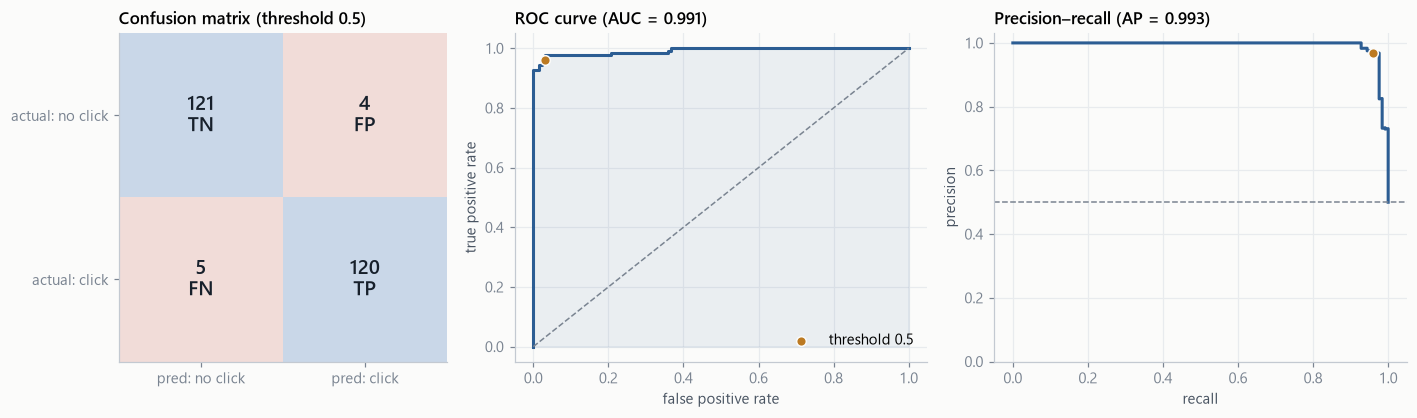

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [0.8, 1, 1]})
cm = np.array([[tn, fp], [fn, tp]])
ax = axes[0]
ax.imshow([[1, 0], [0, 1]], cmap=mpl.colors.ListedColormap(["#F1DCD8", "#C9D7E8"]))
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, f"{v}\n{['TN','FP','FN','TP'][r*2+c]}", ha="center", va="center", fontsize=13, fontweight="semibold", color="#17202B")
ax.set_xticks([0, 1], ["pred: no click", "pred: click"]); ax.set_yticks([0, 1], ["actual: no click", "actual: click"])
ax.grid(False); ax.set_title("Confusion matrix (threshold 0.5)")

fpr, tpr, thr = roc_curve(y_test, prob)
axes[1].plot(fpr, tpr, color=ACCENT, lw=2); axes[1].fill_between(fpr, tpr, color=ACCENT, alpha=.08)
axes[1].plot([0, 1], [0, 1], color="#7A8491", ls="--", lw=1)
axes[1].scatter([fp / (fp + tn)], [rec], color=C1, zorder=3, s=40, edgecolor="#FBFBFA", label="threshold 0.5")
axes[1].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, prob):.3f})"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y_test, prob)
axes[2].plot(rc, pr, color=ACCENT, lw=2); axes[2].axhline(.5, color="#7A8491", ls="--", lw=1)
axes[2].scatter([rec], [prec], color=C1, zorder=3, s=40, edgecolor="#FBFBFA")
axes[2].set_title(f"Precision–recall (AP = {average_precision_score(y_test, prob):.3f})"); axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_ylim(0, 1.03)
fig.tight_layout(); save(fig, "09_evaluation"); plt.show()

In [25]:
# How the decision threshold trades precision for recall
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    yh = (prob >= t).astype(int)
    rows.append([t, accuracy_score(y_test, yh), precision_score(y_test, yh), recall_score(y_test, yh), int(yh.sum())])
pd.DataFrame(rows, columns=["threshold", "accuracy", "precision", "recall", "flagged as click"]).round(3)

,threshold,accuracy,precision,recall,flagged as click
0,0.2,0.916,0.871,0.976,140
1,0.3,0.948,0.924,0.976,132
2,0.4,0.968,0.961,0.976,127
3,0.5,0.964,0.968,0.960,124
4,0.6,0.964,0.968,0.960,124
5,0.7,0.956,0.983,0.928,118
6,0.8,0.960,1.000,0.920,115


## 8. What drives the predictions

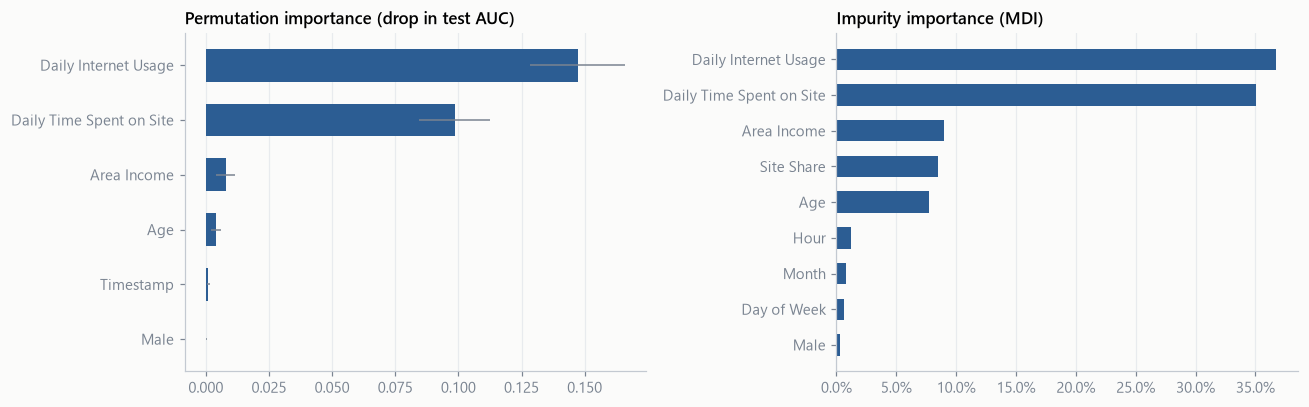

In [26]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=SEED, scoring="roc_auc", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).drop(DROPPED).sort_values()
perm_e = pd.Series(perm.importances_std, index=X_test.columns).drop(DROPPED)[perm_s.index]
mdi = pd.Series(best.named_steps["rf"].feature_importances_, index=FEATURES).sort_values()

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))
a.barh(perm_s.index, perm_s.values, xerr=perm_e.values, color=ACCENT, height=.6, error_kw={"ecolor": "#7A8491", "lw": 1})
a.set_title("Permutation importance (drop in test AUC)"); a.grid(axis="y", visible=False)
b.barh(mdi.index, mdi.values, color=ACCENT, height=.6)
b.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0)); b.set_title("Impurity importance (MDI)"); b.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "10_importance"); plt.show()

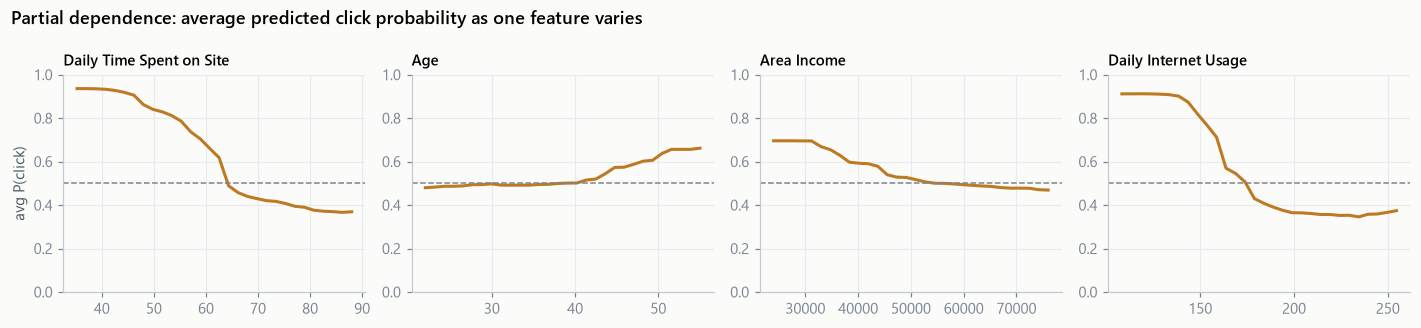

In [27]:
rf = best.named_steps["rf"]; A_full = best.named_steps["features"].transform(X_train)
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axes, NUMERIC_RAW):
    grid = np.linspace(*np.percentile(A_full[col], [2, 98]), 30); pd_vals = []
    for g in grid:
        Z = A_full.copy(); Z[col] = g; Z["Site Share"] = Z["Daily Time Spent on Site"] / Z["Daily Internet Usage"]
        pd_vals.append(rf.predict_proba(Z[FEATURES])[:, 1].mean())
    ax.plot(grid, pd_vals, color=C1, lw=2); ax.axhline(.5, color="#7A8491", ls="--", lw=1)
    ax.set_ylim(0, 1); ax.set_title(col, fontsize=9.5)
axes[0].set_ylabel("avg P(click)")
fig.suptitle("Partial dependence: average predicted click probability as one feature varies", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); save(fig, "11_partial_dependence"); plt.show()

Both importance methods agree that **internet usage and time on site dominate**, followed by area income and age.

* **Timing and gender add almost nothing.** Permutation importance is ~0 for `Timestamp` and `Male`.
* **MDI gives `Hour` a little weight.** Impurity importance is known to favour features with many distinct values,
  which get more chances to split. That is why the permutation view is the more trustworthy one.
* **The partial-dependence curves show the shape of each effect.** Click probability collapses once daily internet
  usage passes ~175 min or time on site passes ~65 min, and it rises with age.

## 9. Comparison with other algorithms

Every model gets the same features and the same split. Scale-sensitive models (Logistic Regression, KNN, SVM) get a
`StandardScaler`. KNN's *k* and the single tree's depth are tuned by CV so that each baseline is fairly strong.

In [28]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import binomtest

scaled = lambda m: Pipeline([("f", FeatureBuilder()), ("s", StandardScaler()), ("m", m)])
plain  = lambda m: Pipeline([("f", FeatureBuilder()), ("m", m)])
k_best = max(range(3, 32, 2), key=lambda k: cross_val_score(scaled(KNeighborsClassifier(k)), X_train, y_train, cv=CV).mean())
d_best = max(range(2, 13), key=lambda d: cross_val_score(plain(DecisionTreeClassifier(max_depth=d, random_state=SEED)), X_train, y_train, cv=CV).mean())

models = {
    "Random Forest (tuned)": best,
    "Random Forest (default)": plain(RandomForestClassifier(random_state=SEED)),
    "Gradient Boosting": plain(GradientBoostingClassifier(random_state=SEED)),
    "AdaBoost": plain(AdaBoostClassifier(random_state=SEED)),
    "Logistic Regression": scaled(LogisticRegression(max_iter=1000)),
    "SVM (RBF)": scaled(CalibratedClassifierCV(SVC(random_state=SEED), ensemble=False)),
    f"KNN (k={k_best})": scaled(KNeighborsClassifier(k_best)),
    "Gaussian Naive Bayes": plain(GaussianNB()),
    f"Decision Tree (depth={d_best})": plain(DecisionTreeClassifier(max_depth=d_best, random_state=SEED)),
}
rows, preds = [], {}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=CV, n_jobs=-1)
    m.fit(X_train, y_train); p = m.predict_proba(X_test)[:, 1]; preds[name] = (p >= .5).astype(int)
    rows.append([name, *scores(p), cv.mean(), accuracy_score(y_train, m.predict(X_train))])
preds["Random Forest (from scratch)"] = (p_s >= .5).astype(int)
rows.append(["Random Forest (from scratch)", *scores(p_s), np.nan, accuracy_score(y_train, scratch.predict(A_train.values))])

table = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "F1", "ROC-AUC", "CV acc", "train acc"]).set_index("model")

# Wilson 95% CI on test accuracy + exact McNemar test vs the tuned forest
n = len(y_test); z = 1.96; ref_ok = preds["Random Forest (tuned)"] == y_test
ci_lo, ci_hi, pvals = [], [], []
for name in table.index:
    ok = preds[name] == y_test; ph = ok.mean()
    c = (ph + z*z/(2*n)) / (1 + z*z/n); h = z*np.sqrt(ph*(1-ph)/n + z*z/(4*n*n)) / (1 + z*z/n)
    ci_lo.append(c - h); ci_hi.append(c + h)
    b_, c_ = int((ref_ok & ~ok).sum()), int((~ref_ok & ok).sum())
    pvals.append(binomtest(b_, b_ + c_, .5).pvalue if b_ + c_ else 1.0)
table["CI low"], table["CI high"], table["McNemar p"] = ci_lo, ci_hi, pvals
table.sort_values("ROC-AUC", ascending=False).round(3)

,accuracy,precision,recall,F1,ROC-AUC,CV acc,train acc,CI low,CI high,McNemar p
model,,,,,,,,,,
Gaussian Naive Bayes,0.976,0.984,0.968,0.976,0.993,0.967,0.967,0.949,0.989,0.250
Logistic Regression,0.980,0.992,0.968,0.980,0.991,0.967,0.971,0.954,0.991,0.125
Random Forest (tuned),0.964,0.968,0.960,0.964,0.991,0.959,0.985,0.933,0.981,1.000
Random Forest (default),0.968,0.976,0.960,0.968,0.990,0.963,1.000,0.938,0.984,1.000
Random Forest (from scratch),0.960,0.960,0.960,0.960,0.989,NaN,1.000,0.928,0.978,1.000
Gradient Boosting,0.960,0.975,0.944,0.959,0.988,0.957,1.000,0.928,0.978,1.000
SVM (RBF),0.960,0.967,0.952,0.960,0.988,0.957,0.977,0.928,0.978,1.000
KNN (k=3),0.968,0.983,0.952,0.967,0.984,0.960,0.969,0.938,0.984,1.000
AdaBoost,0.952,0.945,0.960,0.952,0.980,0.944,0.972,0.918,0.972,0.453


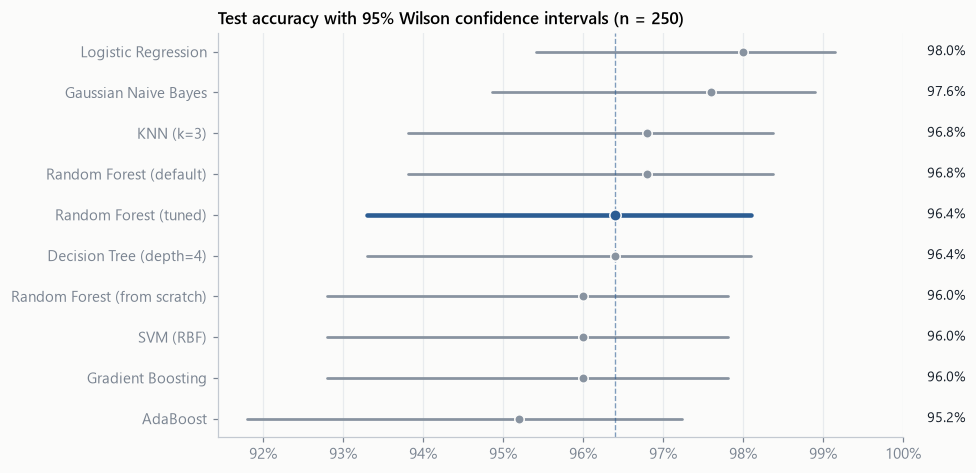

In [29]:
t = table.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, (name, r) in enumerate(t.iterrows()):
    is_ref = name == "Random Forest (tuned)"
    col = ACCENT if is_ref else "#8893A0"
    ax.plot([r["CI low"], r["CI high"]], [i, i], color=col, lw=3 if is_ref else 1.8, solid_capstyle="round")
    ax.scatter(r["accuracy"], i, color=col, s=55 if is_ref else 38, zorder=3, edgecolor="#FBFBFA")
    ax.text(1.003, i, f"{r['accuracy']:.1%}", va="center", fontsize=9, color="#17202B")
ax.axvline(t.loc["Random Forest (tuned)", "accuracy"], color=ACCENT, ls="--", lw=.9, alpha=.6)
ax.set_yticks(range(len(t)), t.index); ax.set_xlim(None, 1.0)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.grid(axis="y", visible=False)
ax.set_title("Test accuracy with 95% Wilson confidence intervals (n = 250)")
fig.tight_layout(); save(fig, "12_comparison"); plt.show()

### Analysis: why the results look like this

**1. The top models are statistically tied.** Logistic Regression scores highest on test accuracy (98.0% vs. the
forest's 96.4%), but that gap is **4 rows out of 250**. All 95% confidence intervals overlap. McNemar's exact test,
which looks only at the rows where two models disagree, gives p ≥ 0.125 for every model against the tuned forest.
None of the differences is significant at 0.05.

**2. Why a linear model does so well here.** Section 2 showed the classes separated by a nearly straight diagonal
in the time-on-site × internet-usage plane, with strong, monotonic, roughly linear effects. A linear boundary is
exactly the right shape. A forest has to approximate that diagonal with many axis-aligned steps, which costs a
few rows right at the boundary. Gaussian Naive Bayes also fits well because each feature's class-conditional
distribution is close to Gaussian.

**3. Why the forest is still the right tool for this task.**
* It **beats a single tree on ranking** (AUC 0.991 vs 0.967), because averaging 167 de-correlated trees cancels
  individual-tree variance.
* It needs **no scaling**, is **robust to outliers**, and captures **non-linear interactions automatically**. Real
  ad logs are far less linear than this dataset.
* It provides **OOB error and feature importance** at no extra cost.

**4. Bagging vs. boosting.** Gradient Boosting (96.0%) and AdaBoost (95.2%) re-weight the hardest examples. Here
those are mostly ambiguous users on the boundary, so the extra focus does not help and AdaBoost slightly overfits
them.

**5. Tuning bought robustness.** The default forest reaches 100% training accuracy (pure memorisation). The tuned
one sits at about 98.5% with the same CV and test performance and a higher AUC. A smaller train–test gap means
more trust on new traffic.

## 10. Interpretation & business insights

In [30]:
u, s_, a_, inc = df["Daily Internet Usage"], df["Daily Time Spent on Site"], df["Age"], df["Area Income"]
facts = {
    "internet usage < 150 min": df[TARGET][u < 150].mean(), "internet usage >= 200 min": df[TARGET][u >= 200].mean(),
    "time on site < 60 min": df[TARGET][s_ < 60].mean(), "time on site >= 75 min": df[TARGET][s_ >= 75].mean(),
    "age >= 45": df[TARGET][a_ >= 45].mean(), "age < 30": df[TARGET][a_ < 30].mean(),
    "area income < $40k": df[TARGET][inc < 40000].mean(), "area income >= $60k": df[TARGET][inc >= 60000].mean(),
}
pd.Series(facts, name="click rate").map("{:.0%}".format).to_frame()

,click rate
internet usage < 150 min,99%
internet usage >= 200 min,7%
time on site < 60 min,96%
time on site >= 75 min,9%
age >= 45,91%
age < 30,25%
area income < $40k,93%
area income >= $60k,28%


**Who clicks?** The model describes a clear audience:

* **Light internet users.** Users online less than 150 min/day click 99% of the time, those online 200+ min only 7%.
  Heavy users are exposed to so many ads that they tune them out (*banner blindness*).
* **Short site visits.** Visitors who spend less than an hour on the site are far more willing to leave it through an
  ad. Long-staying readers came for the content.
* **Older users in lower-income areas** click more. Age and income are secondary but consistent signals.
* **Timing and gender do not matter.** Hour, weekday, month and gender carry essentially no signal.

**What an ad team could do with this model.**
1. **Score before bidding.** Use P(click) as a pre-bid filter. At threshold 0.5, ~97% of flagged impressions are
   real clicks, so far less spend goes to users who will never click.
2. **Set the threshold from economics.** When impressions are cheap and clicks valuable, lower the threshold to catch
   more clickers. When impressions are expensive, raise it (see the threshold table in 7.1).
3. **Change the format for heavy users, not the frequency.** Showing them more banners wastes spend. Native or video
   formats are worth an A/B test.
4. **Skip day-parting premiums.** Timing carries no signal, so time-of-day bid multipliers would add cost without
   lift.

**Limitations.**

* **Easier than real data.** The data is small (1,000 rows), perfectly balanced and unusually clean. Real ad logs
  have click-through rates around 1–2%, which would require class weighting, probability calibration and
  log-loss as the metric.
* **Unused columns.** Ad text and geography were unusable here: unique headlines, and 237 countries for 1,000
  rows. With repeated campaigns, text features and target-encoded country would be worth adding.
* **Correlation, not causation.** The model shows *who* clicks, not *why*. Any targeting change should be validated
  with an A/B test.

## 11. Conclusion
A tuned Random Forest (167 trees, depth ≤ 10, √p features per split, ≥ 4 rows per leaf) predicts ad clicks on unseen
users with **96.4% accuracy, 0.964 F1 and 0.991 ROC-AUC**. A from-scratch NumPy implementation reproduces
scikit-learn's behaviour, which confirms the mechanics of bagging and random feature selection.

On this nearly linearly separable dataset, simpler models perform statistically on par with the forest. The
forest's advantages are robustness, interaction handling and built-in diagnostics, not raw accuracy. The
business value is a clear, data-backed audience profile: light, short-visit, older internet users. The model
turns that profile into an impression-level score.